# Linear Classifiers: Feature Representations

L2 logistic regression and linear svm and lda experiments. Outputs will be saved in 'linear_classifiers_outputs/'

In [1]:
# Versions of libraries make a difference in convergence and reproducibility of the solver. So, fixed it below.
import importlib.metadata as metadata
import subprocess
import sys

PINS = {
    "numpy": "2.3.5",
    "scipy": "1.17.0",
    "pandas": "2.2.3",
    "scikit-learn": "1.8.0",
    "matplotlib": "3.10.8",
}

mismatches = {}
for package_name, required_version in PINS.items():
    try:
        installed_version = metadata.version(package_name)
    except metadata.PackageNotFoundError:
        installed_version = '<not installed>'

    if installed_version != required_version:
        mismatches[package_name] = installed_version

if len(mismatches) > 0:
    print("Installing the project environment; previously installed versions:", mismatches)

    packages_to_install = []
    for package_name, required_version in PINS.items():
        requirement = f"{package_name}=={required_version}"
        packages_to_install.append(requirement)

    command = [sys.executable, "-m", "pip", "install", "-q"]
    command.extend(packages_to_install)
    subprocess.check_call(command)

    # When you upgrade imported binary extensions, you need to restart the kernel
    message = (
        "Packages installed. RESTART your Colab runtime, then Run all again "
        "(needed so imported libraries use the pinned versions)."
    )
    raise RuntimeError(message)

print("Environment pins verified:", PINS)

Environment pins verified: {'numpy': '2.3.5', 'scipy': '1.17.0', 'pandas': '2.2.3', 'scikit-learn': '1.8.0', 'matplotlib': '3.10.8'}


In [2]:
import io
import warnings
from pathlib import Path
from dataclasses import dataclass
from urllib.request import urlopen

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import StratifiedKFold, train_test_split

OUTPUT = Path('linear_classifiers_outputs')
OUTPUT.mkdir(parents=True, exist_ok=True)

MODELS = ['logistic_l2', 'svm_linear', 'lda']
NAMES = {
    'logistic_l2': 'L2 logistic',
    'svm_linear': 'Linear SVM',
    'lda': 'LDA',
}

ATLAS_CFG = {
    'seed': 2026100441,
    'repetitions': 20,
    'atlas': {
        'n': 128,
        'd': 8,
        'test_n': 1024,
        'noise_sd': 0.5,
        'multiplicities': [2, 4, 8],
    },
}
print('Synthetic experiment settings:', ATLAS_CFG)

Synthetic experiment settings: {'seed': 2026100441, 'repetitions': 20, 'atlas': {'n': 128, 'd': 8, 'test_n': 1024, 'noise_sd': 0.5, 'multiplicities': [2, 4, 8]}}


## Synthetic features

20 reps x 8 gaussian features (1 informative). 128 training samples, 1024 test samples. Comparing each transformation vs. original (on held out data).

In [3]:
def duplicate_map(d, coordinate, multiplicity, normalized=False):
    """Map d input features to d + multiplicity - 1 output features."""
    identity_columns = np.eye(d)

    selected_column = identity_columns[:, [coordinate]]
    number_of_extra_copies = multiplicity - 1
    extra_columns = np.repeat(selected_column, number_of_extra_copies, axis=1)

    T = np.concatenate([identity_columns, extra_columns], axis=1)

    if normalized:
        # Give all m copies weight 1/sqrt(m) so their squared weights sum to one.
        normalization = np.sqrt(multiplicity)
        T[coordinate, :] = T[coordinate, :] / normalization

    return T


def canonical_columns(X):
    """Return the first index of each exact-distinct training-set column."""
    keep = []
    number_of_columns = X.shape[1]

    # Only the first occurrence of each exact column is retained.
    for candidate_index in range(number_of_columns):
        already_present = False

        for accepted_index in keep:
            same_values = np.array_equal(
                X[:, candidate_index],
                X[:, accepted_index],
            )
            if same_values:
                already_present = True
                break

        if not already_present:
            keep.append(candidate_index)

    return np.asarray(keep, dtype=int)


def model_factory(name, n):
    """Construct the exact model and hyperparameters used in the atlas."""
    if name == 'logistic_l2':
        regularization_strength = 0.1
        inverse_regularization = 1 / (n * regularization_strength)
        model = LogisticRegression(
            C=inverse_regularization,
            solver='lbfgs',
            tol=1e-10,
            max_iter=10000,
        )
        return model

    if name == 'svm_linear':
        model = SVC(
            C=1.0,
            kernel='linear',
            tol=1e-9,
            max_iter=1000000,
        )
        return model

    if name == 'lda':
        model = LinearDiscriminantAnalysis(solver='svd')
        return model

    raise ValueError(f'Unknown model: {name}')


def evaluate_classifier(name, X, yclass, Xt, ytclass, T):
    """Refit one model and evaluate it on the corresponding held-out samples."""
    # have to do the same transformations for both train and test when comparing scores
    transformed_train = X @ T
    transformed_test = Xt @ T
    model = model_factory(name, len(X))

    # report non-convergence as a failure
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always', ConvergenceWarning)
        model.fit(transformed_train, yclass)
        labels = model.predict(transformed_test)
        prediction = model.decision_function(transformed_test)

    for recorded_warning in caught:
        is_convergence_warning = issubclass(
            recorded_warning.category,
            ConvergenceWarning,
        )
        if is_convergence_warning:
            raise RuntimeError(f'Unresolved convergence in atlas: {name}')

    all_scores_finite = np.isfinite(prediction).all()
    if not all_scores_finite:
        raise RuntimeError(f'Nonfinite atlas scores: {name}')

    incorrectly_classified = labels != ytclass
    classification_error = float(np.mean(incorrectly_classified))

    return {
        'prediction': prediction,
        'labels': labels,
        'task': 'classification',
        'metric': classification_error,
    }

In [4]:
def classifier_atlas_job(cfg, rep):
    settings = cfg['atlas']
    number_of_features = settings['d']
    number_of_training_rows = settings['n']
    number_of_test_rows = settings['test_n']

    seed = cfg['seed'] + 1009 * rep
    rng = np.random.default_rng(seed)

    number_of_rows = number_of_training_rows + number_of_test_rows
    Xall = rng.normal(size=(number_of_rows, number_of_features))
    eps = rng.normal(size=len(Xall))

    signal = Xall[:, 0]
    noise = settings['noise_sd'] * eps
    yall = signal + noise

    # We use a different random stream to replicate the train/test split
    split_rng = np.random.default_rng(seed + 1)
    order = split_rng.permutation(len(Xall))
    train_indices = order[:number_of_training_rows]
    test_indices = order[number_of_training_rows:]

    X = Xall[train_indices]
    y = yall[train_indices]
    Xt = Xall[test_indices]
    yt = yall[test_indices]

    yclass = (y > 0).astype(int)
    ytclass = (yt > 0).astype(int)

    # use a fixed rotation in each repeat to separate the sampling error
    rotation_rng = np.random.default_rng(cfg['seed'] + 9)
    random_square_matrix = rotation_rng.normal(
        size=(number_of_features, number_of_features)
    )
    Q, unused_upper_triangular = np.linalg.qr(random_square_matrix)

    A = np.eye(number_of_features)
    A[0, 0] = 2.0
    A[0, 1] = 0.7

    identity_matrix = np.eye(number_of_features)
    variants = [
        ('original', 'none', 1, identity_matrix, 'raw'),
        ('original', 'none', 1, identity_matrix, 'standardized'),
        ('rotation', 'none', 1, Q, 'raw'),
        ('affine', 'none', 1, A, 'raw'),
    ]

    feature_roles = [('signal', 0), ('noise', number_of_features - 1)]
    for feature_role, feature_index in feature_roles:
        for multiplicity in settings['multiplicities']:
            copy_matrix = duplicate_map(
                number_of_features,
                feature_index,
                multiplicity,
            )

            duplicated_training_data = X @ copy_matrix
            # only using training columns (not held out data) for de-duplication.
            retained_columns = canonical_columns(duplicated_training_data)
            deduplication_matrix = copy_matrix[:, retained_columns]

            normalized_matrix = duplicate_map(
                number_of_features,
                feature_index,
                multiplicity,
                normalized=True,
            )

            variants.append(
                ('duplicate', feature_role, multiplicity, copy_matrix, 'raw')
            )
            variants.append(
                ('duplicate', feature_role, multiplicity, copy_matrix, 'standardized')
            )
            variants.append(
                ('normalized', feature_role, multiplicity, normalized_matrix, 'raw')
            )
            variants.append(
                ('deduplicated', feature_role, multiplicity, deduplication_matrix, 'raw')
            )

    # compare variants to their native representation after the same preprocessing
    baselines = {}
    records = []

    for transformation, feature_role, multiplicity, T, preprocessing in variants:
        if preprocessing == 'standardized':
            center = X.mean(axis=0)
            scale = X.std(axis=0)
            Xwork = (X - center) / scale
            Xtwork = (Xt - center) / scale
        else:
            Xwork = X
            Xtwork = Xt

        transformed_training_data = Xwork @ T
        mapped_back_to_original_coordinates = transformed_training_data @ T.T
        transformed_gram = mapped_back_to_original_coordinates @ Xwork.T
        original_gram = Xwork @ Xwork.T
        gram_difference = transformed_gram - original_gram
        gram_max_change = float(np.max(abs(gram_difference)))

        for name in MODELS:
            result = evaluate_classifier(name, Xwork, yclass, Xtwork, ytclass, T)

            if transformation == 'original':
                baselines[(name, preprocessing)] = result
            base = baselines[(name, preprocessing)]

            # decision scores spot changes that predicted labels can hide
            score_difference = result['prediction'] - base['prediction']
            squared_score_difference = score_difference ** 2
            score_change_mse = float(np.mean(squared_score_difference))
            score_change_max = float(np.max(abs(score_difference)))

            label_disagreement = base['labels'] != result['labels']
            label_change_fraction = float(np.mean(label_disagreement))
            error_change = result['metric'] - base['metric']

            record = {
                'repetition': rep,
                'seed': seed,
                'model': name,
                'task': result['task'],
                'transformation': transformation,
                'feature_role': feature_role,
                'multiplicity': multiplicity,
                'preprocessing': preprocessing,
                'heldout_metric': result['metric'],
                'paired_metric_change': error_change,
                'prediction_change_mse': score_change_mse,
                'prediction_max_abs_change': score_change_max,
                'label_change': label_change_fraction,
                'gram_max_change': gram_max_change,
                'n_train': number_of_training_rows,
                'n_test': len(Xt),
                'representation_dimension': T.shape[1],
            }
            records.append(record)

    number_of_variants = 28
    assert len(records) == number_of_variants * len(MODELS)
    return records

In [5]:
import time

start = time.perf_counter()
all_records = []

for rep in range(ATLAS_CFG['repetitions']):
    repetition_records = classifier_atlas_job(ATLAS_CFG, rep)
    all_records.extend(repetition_records)

atlas = pd.DataFrame(all_records)
atlas_sort_columns = [
    'repetition',
    'model',
    'preprocessing',
    'transformation',
    'feature_role',
    'multiplicity',
]
atlas = atlas.sort_values(atlas_sort_columns)
atlas = atlas.reset_index(drop=True)

assert len(atlas) == 1680
atlas_design_keys = [
    'repetition',
    'model',
    'preprocessing',
    'transformation',
    'feature_role',
    'multiplicity',
]
repeated_design_cells = atlas.duplicated(atlas_design_keys)
assert not repeated_design_cells.any()

atlas_csv_path = OUTPUT / 'linear_classifier_atlas.csv'
atlas.to_csv(atlas_csv_path, index=False, float_format='%.12g')

elapsed_seconds = time.perf_counter() - start
print(f'Generated {len(atlas)} classifier rows in {elapsed_seconds:.1f}s.')
print('Saved:', atlas_csv_path)


Generated 1680 classifier rows in 30.6s.
Saved: linear_classifiers_outputs/linear_classifier_atlas.csv


### Results

Prediction disagreement and paired held-out error, each relative to the original representation.

In [6]:
raw_preprocessing = atlas['preprocessing'] == 'raw'
relevant_transformations = [
    'original',
    'rotation',
    'affine',
    'duplicate',
    'normalized',
    'deduplicated',
]
transformation_selected = atlas['transformation'].isin(relevant_transformations)

selected_multiplicity = (atlas['multiplicity'] == 8) | (atlas['multiplicity'] == 1)
selected_feature_role = (
    (atlas['feature_role'] == 'signal') |
    (atlas['feature_role'] == 'none')
)
selected_rows = (
    raw_preprocessing & transformation_selected &
    selected_multiplicity & selected_feature_role
)
filtered_atlas = atlas[selected_rows]

table_group_columns = ['model', 'transformation', 'multiplicity']
table_groups = filtered_atlas.groupby(table_group_columns, sort=False)
summary_main = table_groups.agg(
    score_mse=('prediction_change_mse', 'mean'),
    score_mse_sd=('prediction_change_mse', 'std'),
    heldout_error=('heldout_metric', 'mean'),
    label_change=('label_change', 'mean'),
)
summary_main = summary_main.reset_index()

print(summary_main.to_string(index=False, float_format=lambda value: f'{value:.6g}'))

      model transformation  multiplicity   score_mse  score_mse_sd  heldout_error  label_change
        lda         affine             1 3.94101e-29   4.91217e-29       0.164307             0
        lda   deduplicated             8           0             0       0.164307             0
        lda      duplicate             8 7.71267e-28   9.97746e-28       0.164307             0
        lda     normalized             8 7.59145e-28   9.90674e-28       0.164307             0
        lda       original             1           0             0       0.164307             0
        lda       rotation             1 5.95883e-29   7.74817e-29       0.164307             0
logistic_l2         affine             1    0.902398      0.189584       0.156934     0.0416504
logistic_l2   deduplicated             8           0             0       0.168213             0
logistic_l2      duplicate             8     1.90562      0.508356       0.153418     0.0462402
logistic_l2     normalized             8

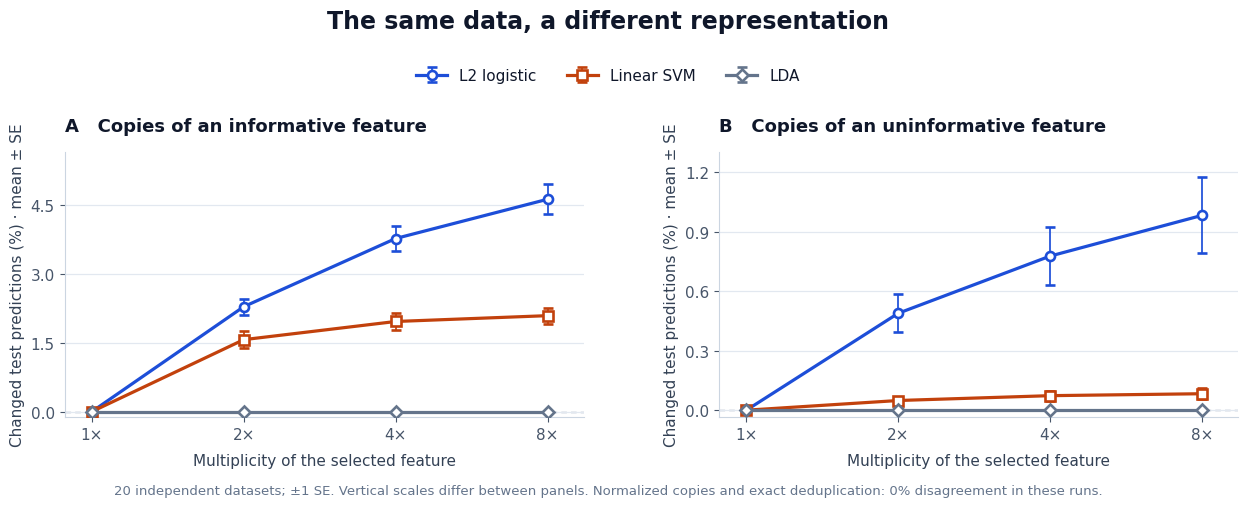

In [7]:
# Publication-oriented figures use paired held-out comparisons, not raw score magnitudes.
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.ticker import MaxNLocator

PLOT_STYLE = {
    'font.family': 'DejaVu Sans',
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.labelsize': 11,
    'axes.edgecolor': '#CBD5E1',
    'axes.labelcolor': '#334155',
    'xtick.color': '#475569',
    'ytick.color': '#475569',
    'text.color': '#0F172A',
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'savefig.facecolor': 'white',
    'svg.fonttype': 'none',
}
plt.rcParams.update(PLOT_STYLE)

MODEL_COLORS = {
    'logistic_l2': '#1D4ED8',
    'svm_linear': '#C2410C',
    'lda': '#64748B',
}
MODEL_MARKERS = {'logistic_l2': 'o', 'svm_linear': 's', 'lda': 'D'}

# Figure 1: fraction of held-out labels changed by duplicating a feature.
# Repetitions are paired with the unmodified fit on the same train/test split.
fig, axes = plt.subplots(1, 2, figsize=(13.0, 5.3))
fig.subplots_adjust(left=0.082, right=0.985, top=0.70, bottom=0.20, wspace=0.26)
roles = [
    ('signal', 'A   Copies of an informative feature'),
    ('noise', 'B   Copies of an uninformative feature'),
]
x_positions = np.arange(4)
copy_counts = [1, 2, 4, 8]

for ax, (role, title) in zip(axes, roles):
    ax.axhline(0, color='#94A3B8', lw=1, ls=(0, (4, 3)), zorder=0)

    for name in MODELS:
        selected = atlas[
            (atlas['model'] == name)
            & (atlas['transformation'] == 'duplicate')
            & (atlas['feature_role'] == role)
            & (atlas['preprocessing'] == 'raw')
        ]
        stats = selected.groupby('multiplicity')['label_change'].agg(
            ['mean', 'std', 'count']
        )
        stats = stats.reindex(copy_counts[1:])
        mean_percentage = np.r_[0, 100 * stats['mean'].to_numpy()]
        se_percentage = np.r_[
            0,
            100 * (stats['std'] / np.sqrt(stats['count'])).to_numpy(),
        ]

        ax.errorbar(
            x_positions,
            mean_percentage,
            yerr=se_percentage,
            color=MODEL_COLORS[name],
            marker=MODEL_MARKERS[name],
            markerfacecolor='white',
            markeredgewidth=1.9,
            markersize=6.5,
            lw=2.3,
            elinewidth=1.25,
            capsize=3.5,
            label=NAMES[name],
            zorder=3,
        )

    ax.set_title(title, loc='left', fontweight='semibold', pad=15)
    ax.set_xticks(x_positions, [f'{count}×' for count in copy_counts])
    ax.set_xlabel('Multiplicity of the selected feature', labelpad=8)
    ax.set_xlim(-0.18, 3.24)
    ax.set_ylim(bottom=-0.08)
    ax.grid(axis='y', color='#E2E8F0', lw=0.9)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
    ax.yaxis.set_major_locator(MaxNLocator(nbins=5))

axes[0].set_ylim(-0.12, 5.65)
axes[1].set_ylim(-0.035, 1.30)
axes[0].set_ylabel('Changed test predictions (%) · mean ± SE')
axes[1].set_ylabel('Changed test predictions (%) · mean ± SE')

legend_handles, legend_names = axes[0].get_legend_handles_labels()
fig.legend(
    legend_handles, legend_names,
    loc='upper center',
    ncol=3,
    frameon=False,
    bbox_to_anchor=(0.5, 0.885),
)
fig.suptitle('The same data, a different representation', fontsize=17, fontweight='bold', y=0.97)
fig.text(
    0.50, 0.055,
    '20 independent datasets; ±1 SE. Vertical scales differ between panels. '
    'Normalized copies and exact deduplication: 0% disagreement in these runs.',
    ha='center', color='#64748B', fontsize=9.5,
)
fig.savefig(OUTPUT / 'linear_classifier_copy_effects.png', dpi=230, bbox_inches='tight')
fig.savefig(OUTPUT / 'linear_classifier_copy_effects.svg', bbox_inches='tight')
plt.show()

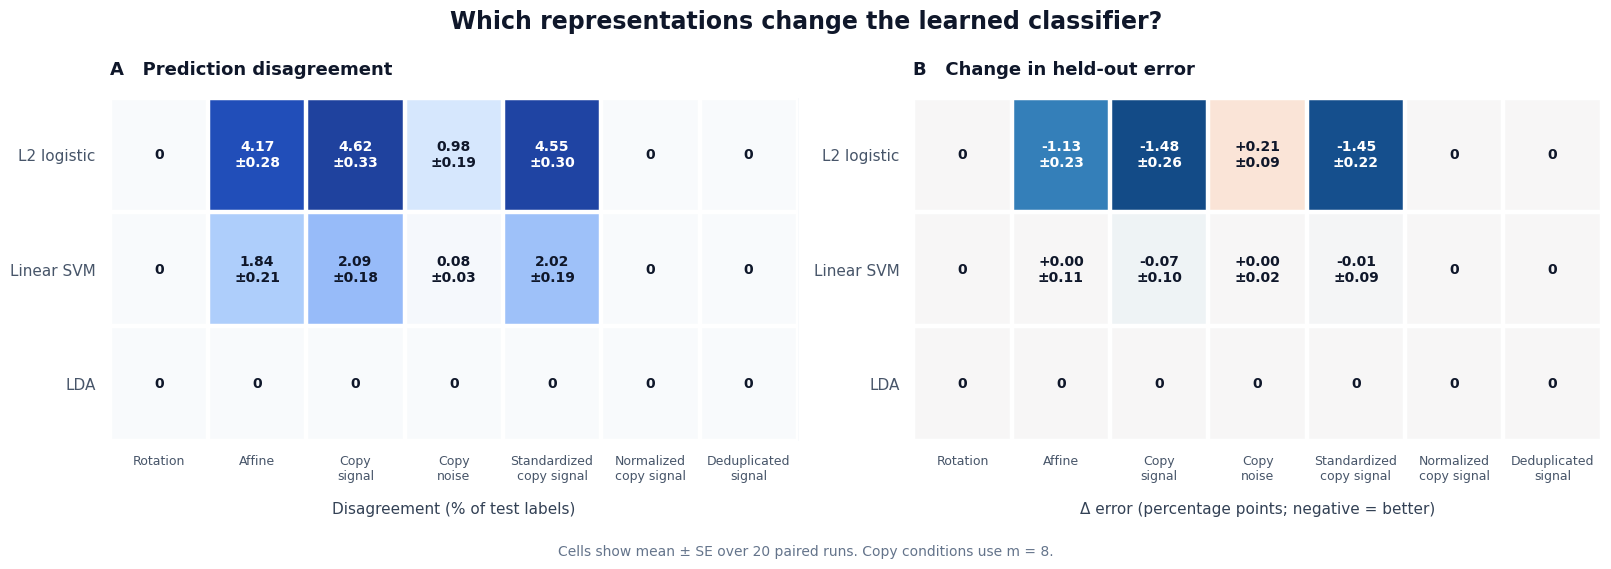

In [8]:
# Figure 2: an invariance map shows both disagreement and change in test error.
# These measure different things: predictions can change without accuracy changing.
conditions = [
    ('Rotation', 'rotation', 'none', 1, 'raw'),
    ('Affine', 'affine', 'none', 1, 'raw'),
    ('Copy\nsignal', 'duplicate', 'signal', 8, 'raw'),
    ('Copy\nnoise', 'duplicate', 'noise', 8, 'raw'),
    ('Standardized\ncopy signal', 'duplicate', 'signal', 8, 'standardized'),
    ('Normalized\ncopy signal', 'normalized', 'signal', 8, 'raw'),
    ('Deduplicated\nsignal', 'deduplicated', 'signal', 8, 'raw'),
]
row_models = MODELS
n_rows = len(row_models)
n_columns = len(conditions)
disagreements = np.zeros((n_rows, n_columns))
error_changes = np.zeros((n_rows, n_columns))
disagreement_se = np.zeros((n_rows, n_columns))
error_change_se = np.zeros((n_rows, n_columns))

for row, model_name in enumerate(row_models):
    for col, (_, transformation, role, copies, prep) in enumerate(conditions):
        selected = atlas[
            (atlas['model'] == model_name)
            & (atlas['transformation'] == transformation)
            & (atlas['feature_role'] == role)
            & (atlas['multiplicity'] == copies)
            & (atlas['preprocessing'] == prep)
        ]
        if len(selected) != ATLAS_CFG['repetitions']:
            raise ValueError(f'Missing atlas comparisons: {model_name}, {transformation}')
        disagreements[row, col] = 100 * selected['label_change'].mean()
        error_changes[row, col] = 100 * selected['paired_metric_change'].mean()
        disagreement_se[row, col] = (
            100 * selected['label_change'].std(ddof=1) / np.sqrt(len(selected))
        )
        error_change_se[row, col] = (
            100 * selected['paired_metric_change'].std(ddof=1) / np.sqrt(len(selected))
        )

blue_scale = LinearSegmentedColormap.from_list(
    'ink_blue', ['#F8FAFC', '#BFDBFE', '#2563EB', '#1E3A8A']
)
fig, (ax_left, ax_right) = plt.subplots(
    1, 2, figsize=(16, 4.65), gridspec_kw={'width_ratios': [1, 1]}, layout='constrained'
)
max_disagreement = max(float(disagreements.max()), 0.01)
max_abs_error = max(float(np.max(np.abs(error_changes))), 0.01)

heatmap_left = ax_left.imshow(
    disagreements, cmap=blue_scale, vmin=0, vmax=max_disagreement * 1.08, aspect='auto'
)
heatmap_right = ax_right.imshow(
    error_changes, cmap='RdBu_r',
    norm=TwoSlopeNorm(vmin=-max_abs_error * 1.12, vcenter=0, vmax=max_abs_error * 1.12),
    aspect='auto',
)

for ax, matrix, standard_errors, heading in [
    (ax_left, disagreements, disagreement_se, 'A   Prediction disagreement'),
    (ax_right, error_changes, error_change_se, 'B   Change in held-out error'),
]:
    ax.set_title(heading, loc='left', fontweight='semibold', pad=17)
    ax.set_yticks(range(n_rows), [NAMES[name] for name in row_models])
    ax.set_xticks(range(n_columns), [item[0] for item in conditions])
    ax.tick_params(axis='x', length=0, labelsize=9, pad=10)
    ax.tick_params(axis='y', length=0, pad=10)
    ax.spines[:].set_visible(False)
    ax.set_xticks(np.arange(-0.5, n_columns, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, n_rows, 1), minor=True)
    ax.grid(which='minor', color='white', linewidth=3.2)
    ax.tick_params(which='minor', bottom=False, left=False)

    for row in range(n_rows):
        for col in range(n_columns):
            value = matrix[row, col]
            se = standard_errors[row, col]
            if abs(value) < 0.005 and se < 0.005:
                label = '0'
            else:
                if ax is ax_left:
                    mean_label = f'{value:.2f}'
                else:
                    mean_label = f'{value:+.2f}'
                label = mean_label + chr(10) + f'±{se:.2f}'
            if ax is ax_left:
                text_color = 'white' if value > max_disagreement * 0.62 else '#0F172A'
            else:
                text_color = 'white' if abs(value) > max_abs_error * 0.63 else '#0F172A'
            ax.text(col, row, label, ha='center', va='center',
                    color=text_color, fontsize=10, fontweight='semibold')

ax_left.set_xlabel('Disagreement (% of test labels)', labelpad=14)
ax_right.set_xlabel('Δ error (percentage points; negative = better)', labelpad=14)
fig.suptitle('Which representations change the learned classifier?', fontsize=17,
             fontweight='bold', y=1.10)
fig.text(0.5, -0.075, 'Cells show mean ± SE over 20 paired runs. Copy conditions use m = 8.',
         ha='center', fontsize=10, color='#64748B')
fig.savefig(OUTPUT / 'linear_classifier_representation_comparison.png',
            dpi=230, bbox_inches='tight')
fig.savefig(OUTPUT / 'linear_classifier_representation_comparison.svg',
            bbox_inches='tight')
plt.show()

## Parkinson's voice data: logistic regression

50 repeated subject-held-out splits. Compare fixed regularization with regularization selected by grouped or row-wise cross-validation. Fit preprocessing within each training fold.

Data: [UCI Parkinson's dataset](https://archive.ics.uci.edu/dataset/174/parkinsons). Data are downloaded from UCI when no local copy is available.

In [9]:
NATURAL_CFG = {
    'seed': 2026100507,
    'natural': {
        'repetitions': 50,
        'test_fraction': 0.3,
        'inner_folds': 3,
        'lambdas': [
            0.0001,
            0.000215443469,
            0.000464158883,
            0.001,
            0.00215443469,
            0.00464158883,
            0.01,
            0.0215443469,
            0.0464158883,
            0.1,
            0.215443469,
            0.464158883,
            1.0,
        ],
        'multiplicity': 8,
        'redundant_delta': 0.05,
        'thresholds': [0.95, 0.99, 0.999],
    },
}
SOURCE = 'https://archive.ics.uci.edu/static/public/174/parkinsons.zip'


def load_voice_data():
    """Load voice measurements, labels, and subject IDs."""
    csv_path = OUTPUT / 'parkinsons.csv'

    if csv_path.is_file():
        frame = pd.read_csv(csv_path)
    else:
        archive_path = OUTPUT / 'parkinsons.zip'
        if archive_path.is_file():
            archive_bytes = archive_path.read_bytes()
        else:
            archive_bytes = urlopen(SOURCE, timeout=60).read()

        import zipfile
        with zipfile.ZipFile(io.BytesIO(archive_bytes)) as archive:
            with archive.open('parkinsons.data') as csv_file:
                frame = pd.read_csv(csv_file)

        # Use the same cached representation on first and later runs.
        frame.to_csv(csv_path, index=False, float_format='%.12g')
        frame = pd.read_csv(csv_path)

    if frame.shape != (195, 24):
        raise ValueError(f'Unexpected voice-data dimensions: {frame.shape}')
    if frame.isna().any().any():
        raise ValueError('Voice dataset has missing measurements.')

    speaker_groups = frame['name'].str.rsplit('_', n=1).str[0]
    subject_status = frame.groupby(speaker_groups)['status'].nunique()
    if len(subject_status) != 32 or not subject_status.eq(1).all():
        raise ValueError('Subject IDs or class labels are inconsistent.')

    predictor_frame = frame.drop(columns=['name', 'status'])
    X = predictor_frame.to_numpy(float)
    y = frame['status'].to_numpy(int)
    groups = speaker_groups.to_numpy()

    return X, y, groups


In [10]:
def group_average(values, groups):
    """Average within subjects first, then give each subject equal weight."""
    distinct_groups, group_index = np.unique(groups, return_inverse=True)

    # Average per subject so subjects with more recordings do not dominate.
    group_totals = np.bincount(group_index, weights=values)
    group_sizes = np.bincount(group_index)
    group_means = group_totals / group_sizes
    return float(np.mean(group_means))


def choose_index(scores, eligible=None, tie_tolerance=1e-12):
    """Pick the first eligible grid position within tolerance of the best."""
    if eligible is None:
        eligible_indices = np.arange(len(scores))
    else:
        eligible_indices = np.asarray(eligible)

    eligible_scores = scores[eligible_indices]
    smallest_score = float(np.min(eligible_scores))
    acceptable_score_limit = smallest_score + tie_tolerance
    acceptable_scores = eligible_scores <= acceptable_score_limit

    # The first candidate within tolerance wins tied grid searches.
    positions_inside_eligible = np.flatnonzero(acceptable_scores)
    first_matching_position = positions_inside_eligible[0]
    selected_grid_index = eligible_indices[first_matching_position]
    return int(selected_grid_index)


def greedy_correlation_columns(X, threshold):
    """Retain columns in order unless correlated with an earlier retained one."""
    column_correlations = np.corrcoef(X.T)
    keep = []

    for candidate_index in range(X.shape[1]):
        too_correlated = False
        for accepted_index in keep:
            absolute_correlation = abs(column_correlations[candidate_index, accepted_index])
            if absolute_correlation >= threshold:
                too_correlated = True
                break

        if not too_correlated:
            keep.append(candidate_index)

    return np.asarray(keep, int)


@dataclass
class NaturalPrep:
    mean: np.ndarray
    scale: np.ndarray
    matrix: np.ndarray

    @classmethod
    def fit(cls, X, transformation, cfg):
        # Estimate scaling only on the current training partition.
        mean = X.mean(0)
        raw_scale = X.std(0)
        scale = np.where(raw_scale > 1e-12, raw_scale, 1.0)
        Z = (X - mean) / scale

        number_of_features = X.shape[1]
        T = np.eye(number_of_features)

        if transformation == 'copies':
            T = duplicate_map(
                number_of_features,
                0,
                cfg['multiplicity'],
            )

        elif transformation == 'normalized':
            T = duplicate_map(
                number_of_features,
                0,
                cfg['multiplicity'],
                normalized=True,
            )

        # Near-copies differ from exact copies by a second feature contribution.
        elif transformation == 'correlated':
            extra_column = np.zeros((number_of_features, 1))
            extra_column[0] = 1
            extra_column[1] = cfg['redundant_delta']
            number_of_extra_copies = cfg['multiplicity'] - 1
            repeated_columns = np.repeat(extra_column, number_of_extra_copies, axis=1)
            T = np.column_stack([T, repeated_columns])

        elif transformation.startswith('prune_'):
            threshold_text = transformation.split('_')[1]
            threshold = float(threshold_text)
            kept_feature_indices = greedy_correlation_columns(Z, threshold)
            T = T[:, kept_feature_indices]

        elif transformation != 'native':
            raise ValueError(transformation)

        return cls(mean, scale, T)

    def transform(self, X):
        centered = X - self.mean
        standardized = centered / self.scale
        transformed = standardized @ self.matrix
        return transformed


def natural_folds(y, groups, seed, mode, k):
    """Build row-stratified or subject-stratified CV folds."""
    splitter = StratifiedKFold(k, shuffle=True, random_state=seed)

    if mode == 'naive':
        dummy_features = np.zeros(len(y))
        split_iterator = splitter.split(dummy_features, y)
        return list(split_iterator)

    # Grouped folds split subject IDs, then map those IDs back to recordings.
    unique_subjects, first_recording_positions = np.unique(groups, return_index=True)
    subject_labels = y[first_recording_positions]
    subject_split_iterator = splitter.split(unique_subjects, subject_labels)

    folds = []
    for subject_train_positions, subject_validation_positions in subject_split_iterator:
        train_subjects = unique_subjects[subject_train_positions]
        validation_subjects = unique_subjects[subject_validation_positions]

        train_membership = np.isin(groups, train_subjects)
        validation_membership = np.isin(groups, validation_subjects)
        train_positions = np.flatnonzero(train_membership)
        validation_positions = np.flatnonzero(validation_membership)

        folds.append((train_positions, validation_positions))

    return folds


def natural_logistic_predict(Z, y, Zt, lam):
    """Fit L2 logistic regression and return positive-class probabilities."""
    number_of_training_observations = len(y)
    inverse_regularization = 1 / (number_of_training_observations * lam)

    estimator = LogisticRegression(
        C=inverse_regularization,
        solver='lbfgs',
        tol=1e-8,
        max_iter=10000,
    )

    with warnings.catch_warnings():
        warnings.simplefilter('error', ConvergenceWarning)
        fitted_estimator = estimator.fit(Z, y)

    probabilities_for_both_classes = fitted_estimator.predict_proba(Zt)
    positive_class_probabilities = probabilities_for_both_classes[:, 1]
    return positive_class_probabilities

In [11]:
def natural_logistic_job(cfg, rep, X, y, groups):
    settings = cfg['natural']
    seed = cfg['seed'] + 200000 + 1009 * rep

    unique_subjects, first_recording_positions = np.unique(groups, return_index=True)
    subject_labels = y[first_recording_positions]

    # The outer test set holds out entire subjects.
    train_ids, test_ids = train_test_split(
        unique_subjects,
        test_size=settings['test_fraction'],
        stratify=subject_labels,
        random_state=seed,
    )

    training_row_mask = np.isin(groups, train_ids)
    test_row_mask = np.isin(groups, test_ids)
    train_rows = np.flatnonzero(training_row_mask)
    test_rows = np.flatnonzero(test_row_mask)

    outer_train_features = X[train_rows]
    outer_train_labels = y[train_rows]
    outer_train_groups = groups[train_rows]
    outer_test_features = X[test_rows]
    outer_test_labels = y[test_rows]
    outer_test_groups = groups[test_rows]

    records = []
    transformations = ['native', 'copies', 'normalized', 'correlated']
    for threshold in settings['thresholds']:
        transformations.append(f'prune_{threshold:g}')

    for mode in ['grouped', 'naive']:
        folds = natural_folds(
            outer_train_labels,
            outer_train_groups,
            seed + 1,
            mode,
            settings['inner_folds'],
        )

        leaked_recordings = 0
        for fold_train_rows, fold_validation_rows in folds:
            fold_training_groups = outer_train_groups[fold_train_rows]
            fold_validation_groups = outer_train_groups[fold_validation_rows]
            seen_speakers = np.isin(fold_validation_groups, fold_training_groups)
            leaked_recordings += seen_speakers.sum()
        leaked = leaked_recordings / len(outer_train_groups)

        # Subject-grouped validation must contain no training subjects.
        if mode == 'grouped':
            assert leaked == 0

        if mode == 'grouped':
            mode_transformations = transformations
        else:
            mode_transformations = ['native']

        for transformation in mode_transformations:
            number_of_lambdas = len(settings['lambdas'])
            number_of_train_rows = len(outer_train_labels)

            # Each held-out recording receives one CV prediction per lambda.
            oof = np.empty((number_of_train_rows, number_of_lambdas))

            for fold_train_rows, fold_validation_rows in folds:
                fold_train_features = outer_train_features[fold_train_rows]
                fold_train_labels = outer_train_labels[fold_train_rows]
                fold_validation_features = outer_train_features[fold_validation_rows]

                # Refit preprocessing inside every inner training fold.
                prep = NaturalPrep.fit(fold_train_features, transformation, settings)
                Z = prep.transform(fold_train_features)
                Zv = prep.transform(fold_validation_features)

                for lambda_index, lam in enumerate(settings['lambdas']):
                    predicted_probabilities = natural_logistic_predict(
                        Z,
                        fold_train_labels,
                        Zv,
                        lam,
                    )
                    oof[fold_validation_rows, lambda_index] = predicted_probabilities

            # Select lambda by subject-weighted, not row-weighted, Brier error.
            scores_per_lambda = []
            for lambda_index in range(number_of_lambdas):
                probabilities = oof[:, lambda_index]
                squared_errors = (probabilities - outer_train_labels) ** 2
                cv_score = group_average(squared_errors, outer_train_groups)
                scores_per_lambda.append(cv_score)
            scores = np.array(scores_per_lambda)

            selected_lambda_index = choose_index(scores)
            selected_lambda = settings['lambdas'][selected_lambda_index]
            selected_cv_score = float(scores[selected_lambda_index])

            # Fit final preprocessing on all outer-training observations.
            prep = NaturalPrep.fit(outer_train_features, transformation, settings)
            Z = prep.transform(outer_train_features)
            Ztest = prep.transform(outer_test_features)

            evaluated_models = [
                ('logistic_cv', selected_lambda, selected_cv_score),
                ('logistic_fixed', 0.1, None),
            ]

            for name, lam, cv in evaluated_models:
                pred = natural_logistic_predict(Z, outer_train_labels, Ztest, lam)

                squared_test_errors = (pred - outer_test_labels) ** 2
                test_brier = group_average(squared_test_errors, outer_test_groups)

                predicted_test_labels = pred >= 0.5
                correct_predictions = predicted_test_labels == outer_test_labels
                correct_as_floats = correct_predictions.astype(float)
                test_accuracy = group_average(correct_as_floats, outer_test_groups)

                if cv is None:
                    optimism = None
                else:
                    optimism = test_brier - cv

                first_grid_lambda = settings['lambdas'][0]
                last_grid_lambda = settings['lambdas'][-1]
                at_grid_endpoint = lam in [first_grid_lambda, last_grid_lambda]

                record = {
                    'rep': rep,
                    'cv_mode': mode,
                    'transformation': transformation,
                    'model': name,
                    'selected_family': 'logistic',
                    'parameter': float(lam),
                    'test_brier': test_brier,
                    'test_accuracy': test_accuracy,
                    'cv_brier': cv,
                    'optimism': optimism,
                    'leaked_validation_fraction': float(leaked),
                    'features_kept': int(Z.shape[1]),
                    'train_subjects': len(train_ids),
                    'test_subjects': len(test_ids),
                    'grid_endpoint': at_grid_endpoint,
                }
                records.append(record)

    return records

In [12]:
VOICE_RAN = False
natural = None

try:
    voice_X, voice_y, voice_groups = load_voice_data()
except (OSError, TimeoutError) as exc:
    print('Parkinson\'s data unavailable; skipped the voice-data experiment.')
    print(type(exc).__name__, str(exc)[:280])
else:
    start = time.perf_counter()
    natural_rows = []
    number_of_repetitions = NATURAL_CFG['natural']['repetitions']

    for rep in range(number_of_repetitions):
        repetition_rows = natural_logistic_job(
            NATURAL_CFG,
            rep,
            voice_X,
            voice_y,
            voice_groups,
        )
        natural_rows.extend(repetition_rows)

        completed_repetitions = rep + 1
        if completed_repetitions % 10 == 0:
            print(f'Completed logistic voice replication {completed_repetitions}/{number_of_repetitions}')

    natural = pd.DataFrame(natural_rows)
    natural_sort_columns = ['rep', 'cv_mode', 'transformation', 'model']
    natural = natural.sort_values(natural_sort_columns)
    natural = natural.reset_index(drop=True)

    assert len(natural) == 800
    repeated_rows = natural.duplicated(natural_sort_columns)
    assert not repeated_rows.any()

    natural_csv_path = OUTPUT / 'natural_logistic.csv'
    natural.to_csv(natural_csv_path, index=False, float_format='%.12g')
    VOICE_RAN = True

    elapsed_seconds = time.perf_counter() - start
    print(f'Generated {len(natural)} voice logistic rows in {elapsed_seconds:.1f}s.')

Completed logistic voice replication 10/50
Completed logistic voice replication 20/50
Completed logistic voice replication 30/50
Completed logistic voice replication 40/50
Completed logistic voice replication 50/50
Generated 800 voice logistic rows in 223.5s.


In [13]:
if VOICE_RAN:
    # Pair each transformed run with its native run from the same repetition.
    grouped_cv_rows = natural[natural['cv_mode'] == 'grouped']
    comparison = grouped_cv_rows.pivot(
        index='rep',
        columns=['transformation', 'model'],
        values='test_brier',
    )

    for name in ['logistic_cv', 'logistic_fixed']:
        base = comparison[('native', name)]
        print(f'\nPaired Brier changes vs native: {name}')

        other_transformations = [
            'copies',
            'correlated',
            'normalized',
            'prune_0.95',
            'prune_0.99',
            'prune_0.999',
        ]
        for transformation in other_transformations:
            treatment_brier = comparison[(transformation, name)]
            changes = treatment_brier - base
            mean_change = changes.mean()
            change_sd = changes.std(ddof=1)
            print(f'  {transformation:12s}: {mean_change:+.7f} ± {change_sd:.7f} (SD, n=50)')



Paired Brier changes vs native: logistic_cv
  copies      : -0.0043424 ± 0.0146292 (SD, n=50)
  correlated  : -0.0046981 ± 0.0145802 (SD, n=50)
  normalized  : -0.0000000 ± 0.0000000 (SD, n=50)
  prune_0.95  : -0.0017662 ± 0.0144682 (SD, n=50)
  prune_0.99  : -0.0026548 ± 0.0144176 (SD, n=50)
  prune_0.999 : -0.0025676 ± 0.0142453 (SD, n=50)

Paired Brier changes vs native: logistic_fixed
  copies      : +0.0046498 ± 0.0112708 (SD, n=50)
  correlated  : +0.0043036 ± 0.0109652 (SD, n=50)
  normalized  : +0.0000000 ± 0.0000000 (SD, n=50)
  prune_0.95  : -0.0006596 ± 0.0051957 (SD, n=50)
  prune_0.99  : -0.0012143 ± 0.0017471 (SD, n=50)
  prune_0.999 : -0.0007465 ± 0.0009159 (SD, n=50)


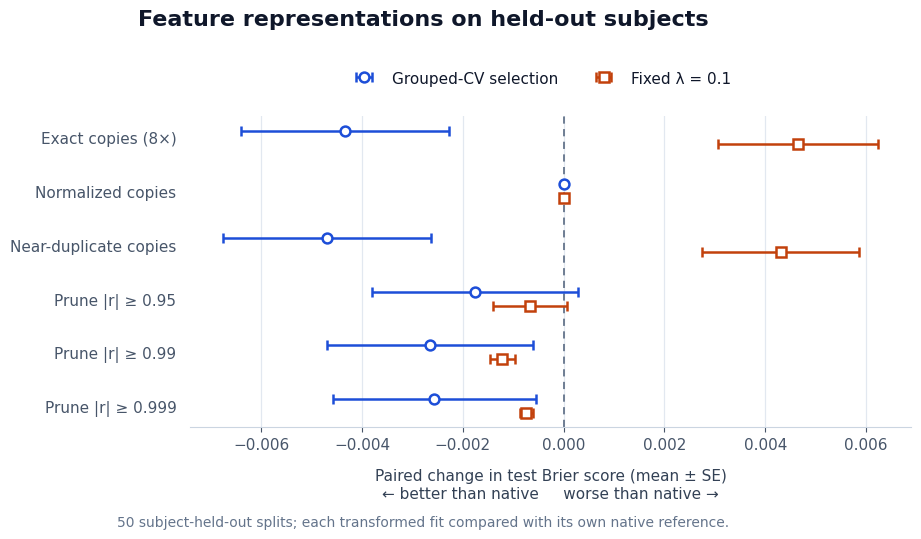

In [14]:
if VOICE_RAN:
    grouped_results = natural[natural['cv_mode'] == 'grouped']
    grouped_brier = grouped_results.pivot(
        index='rep', columns=['transformation', 'model'], values='test_brier'
    )

    treatments = [
        ('copies', 'Exact copies (8×)'),
        ('normalized', 'Normalized copies'),
        ('correlated', 'Near-duplicate copies'),
        ('prune_0.95', 'Prune |r| ≥ 0.95'),
        ('prune_0.99', 'Prune |r| ≥ 0.99'),
        ('prune_0.999', 'Prune |r| ≥ 0.999'),
    ]
    fit_types = [
        ('logistic_cv', 'Grouped-CV selection', '#1D4ED8', 'o', -0.13),
        ('logistic_fixed', 'Fixed λ = 0.1', '#C2410C', 's', 0.13),
    ]

    # Paired differences eliminate variation due to the subject split shared
    # between a transformed fit and its native counterpart.
    fig, ax = plt.subplots(figsize=(10.6, 5.65))
    fig.subplots_adjust(left=0.28, right=0.96, top=0.77, bottom=0.22)
    y_positions = np.arange(len(treatments))
    ax.axvline(0, color='#64748B', lw=1.3, ls=(0, (4, 3)), zorder=1)

    for model_name, label, color, marker, offset in fit_types:
        baseline_brier = grouped_brier[('native', model_name)]
        paired_means = []
        paired_se = []

        for transformation, _ in treatments:
            transformed_brier = grouped_brier[(transformation, model_name)]
            paired_differences = transformed_brier - baseline_brier
            paired_means.append(float(paired_differences.mean()))
            paired_se.append(float(paired_differences.std(ddof=1)) / np.sqrt(len(paired_differences)))

        ax.errorbar(
            paired_means, y_positions + offset, xerr=paired_se,
            fmt=marker, color=color, markerfacecolor='white',
            markeredgewidth=1.8, markersize=7.1, elinewidth=1.8,
            capsize=3.5, linestyle='none', label=label, zorder=3,
        )

    ax.set_yticks(y_positions, [label for _, label in treatments])
    ax.invert_yaxis()
    ax.set_xlabel('Paired change in test Brier score (mean ± SE)\n← better than native     worse than native →',
                  labelpad=12)
    fig.suptitle('Feature representations on held-out subjects',
                 fontsize=16, fontweight='bold', y=0.96)
    ax.grid(axis='x', color='#E2E8F0', lw=0.9)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right', 'left']].set_visible(False)
    ax.tick_params(axis='y', length=0, pad=10)
    handles, labels = ax.get_legend_handles_labels()
    fig.legend(handles, labels, loc='upper center', frameon=False, ncol=2,
               bbox_to_anchor=(0.61, 0.875))
    fig.text(0.5, 0.045,
             '50 subject-held-out splits; each transformed fit compared with its own native reference.',
             ha='center', color='#64748B', fontsize=10)
    fig.savefig(OUTPUT / 'natural_logistic_results.png', dpi=230, bbox_inches='tight')
    fig.savefig(OUTPUT / 'natural_logistic_paired_changes.png', dpi=230, bbox_inches='tight')
    fig.savefig(OUTPUT / 'natural_logistic_results.svg', bbox_inches='tight')
    plt.show()

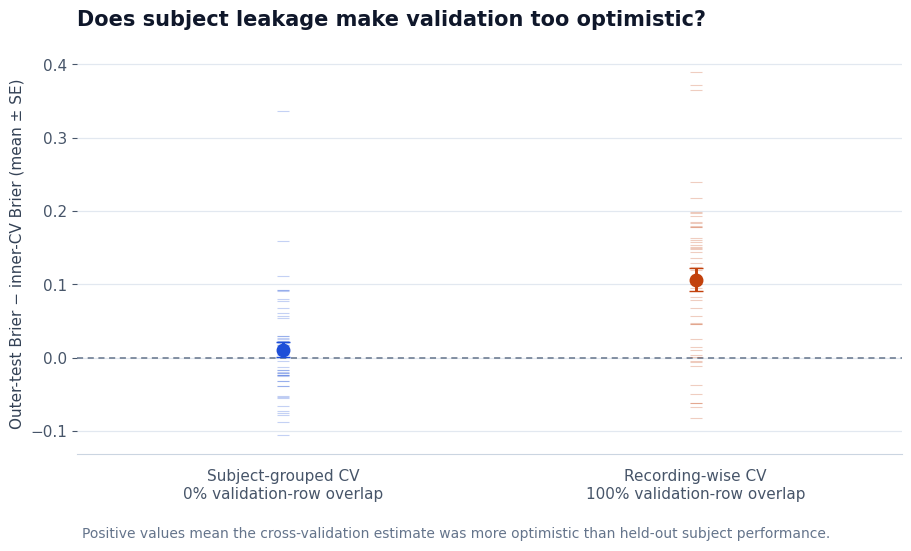

In [15]:
if VOICE_RAN:
    # The CV optimism plot addresses a different issue: row-wise CV can reuse
    # recordings of the same subjects between its training and validation folds.
    natural_native = natural[
        (natural['transformation'] == 'native')
        & (natural['model'] == 'logistic_cv')
    ]
    validation_modes = [('grouped', 'Subject-grouped CV', '#1D4ED8'),
                        ('naive', 'Recording-wise CV', '#C2410C')]

    fig, ax = plt.subplots(figsize=(9, 5.0), layout='constrained')
    mode_tick_labels = []
    ax.axhline(0, color='#64748B', lw=1.1, ls=(0, (4, 3)))
    for index, (mode, label, color) in enumerate(validation_modes):
        values = natural_native.loc[
            natural_native['cv_mode'] == mode, 'optimism'
        ].to_numpy()
        mean = float(values.mean())
        se = float(values.std(ddof=1)) / np.sqrt(len(values))
        x = index

        # Thin vertical ticks preserve the split-to-split spread while the
        # large point and whiskers show the across-split mean and SE.
        ax.scatter(np.repeat(x, len(values)), values, marker='_', s=75,
                   lw=0.8, color=color, alpha=0.26, zorder=2)
        ax.errorbar(x, mean, yerr=se, fmt='o', ms=9, capsize=5,
                    color=color, ecolor=color, elinewidth=2.1, zorder=4)
        leakage = natural_native.loc[
            natural_native['cv_mode'] == mode, 'leaked_validation_fraction'
        ].mean()
        mode_tick_labels.append(label + chr(10) + f'{leakage:.0%} validation-row overlap')

    ax.set_xticks([0, 1], mode_tick_labels)
    ax.set_xlim(-0.5, 1.5)
    ax.set_ylabel('Outer-test Brier − inner-CV Brier (mean ± SE)')
    ax.set_title('Does subject leakage make validation too optimistic?',
                 loc='left', fontsize=15, fontweight='semibold', pad=20)
    ax.grid(axis='y', color='#E2E8F0', lw=0.9)
    ax.spines[['top', 'right', 'left']].set_visible(False)
    ax.tick_params(axis='x', length=0, pad=11)
    fig.text(0.5, -0.065,
             'Positive values mean the cross-validation estimate was more optimistic '
             'than held-out subject performance.',
             ha='center', color='#64748B', fontsize=10)
    fig.savefig(OUTPUT / 'natural_logistic_cv_optimism.png', dpi=230, bbox_inches='tight')
    fig.savefig(OUTPUT / 'natural_logistic_cv_optimism.svg', bbox_inches='tight')
    plt.show()
else:
    print('Parkinson’s figures will be generated once the voice dataset is available.')